# 02. Ручное обогащение текстового набора

| Параметр | Значение |
|---|---|
| Данные | 150 SMS: NUS SMS Corpus, SMS Phishing Dataset (Mishra, Soni); дата обращения 01.11.2026 |
| Скрипты | `src/build_sms_enrichment.py`, `src/finalize_enrichment.py` |
| Исполнители | Якунченков К. А., Графов Г. П. |

Содержание: состав пополнения, отсутствие пересечения с UCI, сравнение распределений признаков,
качество базовой модели, обученной на UCI, на собранных сообщениях.

## 0. Окружение

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.pipeline import Pipeline

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TABLES, FIGURES = ROOT / "reports/tables", ROOT / "reports/figures"
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42
pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 80)

uci = pd.read_csv(ROOT / "data/raw/uci/SMSSpamCollection", sep="\t", header=None, names=["label", "text"],
                  quoting=3, dtype=str)
new = pd.read_csv(ROOT / "data/interim/sms_enrichment/sms_enrichment_manifest.csv")
print(f"UCI: {len(uci)} | собранных SMS: {len(new)}")

UCI: 5574 | собранных SMS: 150


## 1. Состав пополнения

Квоты страт заданы в `QUOTA` скрипта сбора. `label_src` — метка источника: NUS (личная переписка) — ham;
Mishra & Soni — метки авторов набора, класс `smishing` приведён к `spam`.

In [2]:
comp = new.groupby(["label_src", "stratum", "source"]).size().rename("сообщений").reset_index()
display(comp)
comp.to_csv(TABLES / "sms_enrichment_composition.csv", index=False)

rel = pd.DataFrame({"UCI": uci.label.value_counts(), "добавлено": new.label_src.value_counts()})
rel["прирост класса, %"] = (rel["добавлено"] / rel["UCI"] * 100).round(1)
display(rel)
print("Лицензии:", new.license.value_counts().to_dict())
print("Обезличено сообщений:", int(new.anonymised.sum()))

,label_src,stratum,source,сообщений
0,ham,ham_mishra,Mishra,35
1,ham,ham_personal_other,NUS,20
2,ham,ham_personal_sg,NUS,20
3,spam,spam_promo,Mishra,35
4,spam,spam_smishing,Mishra,40


,UCI,добавлено,"прирост класса, %"
ham,4827,75,1.6
spam,747,75,10.0


Лицензии: {'CC BY 4.0 (https://creativecommons.org/licenses/by/4.0/)': 150}
Обезличено сообщений: 0


## 2. Отсутствие пересечения с UCI

Уровни проверки: точное совпадение; совпадение шаблона после нормализации; косинусная близость TF-IDF
символьных 3–5-грамм не менее 0,80.

In [3]:
dedup = pd.read_csv(ROOT / "data/interim/sms_enrichment/sms_enrichment_report.csv", index_col=0)
display(dedup)
print(f"Максимальная близость отобранного сообщения к UCI: {new.max_cos_uci.max():.3f} "
      f"(медиана {new.max_cos_uci.median():.3f}); порог 0,80")

,значение
"NUS, сообщений в корпусе",55835
"Mishra, сообщений в корпусе",5971
NUS: точных совпадений с UCI,3776
NUS: шаблонных совпадений с UCI,26
NUS: почти-дублей (cos >= 0.8),774
NUS: прошло фильтр,37495
Mishra: точных совпадений с UCI,4754
Mishra: шаблонных совпадений с UCI,311
Mishra: почти-дублей (cos >= 0.8),431
Mishra: прошло фильтр,361


Максимальная близость отобранного сообщения к UCI: 0.799 (медиана 0.364); порог 0,80


## 3. Сравнение распределений

Длина сообщения: тесты Манна — Уитни и Колмогорова — Смирнова по каждому классу. Бинарные признаки: доли.

,класс,медиана длины UCI,медиана длины новых,Манн-Уитни p,KS D,KS p,"ссылка, % UCI / новых","телефон, % UCI / новых","валюта/сумма, % UCI / новых"
0,ham,53.0,44.0,0.0243,0.1297,0.1529,0.2 / 0.0,0.1 / 0.0,0.4 / 0.0
1,spam,148.0,149.0,0.7070,0.0785,0.7691,18.2 / 42.7,54.4 / 49.3,33.7 / 16.0


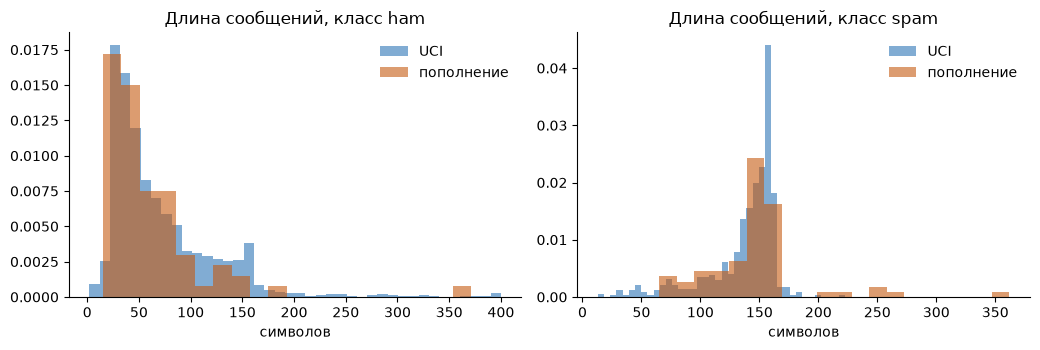

In [4]:
URL_RE = re.compile(r"(?:https?://\S+|www\.\S+|\b[a-z0-9-]+\.(?:com|net|org|io|ly|co|uk|me|info|biz|xyz)\b)", re.I)
PHONE_RE = re.compile(r"(?<!\w)(?:\+?\d[\d\s\-()]{6,}\d)(?!\w)")
CUR_RE = re.compile(r"[£$€]|\b(?:rs|gbp|usd|inr|aud)\.?\s?\d", re.I)


def feats(df, label_col):
    return pd.DataFrame({"label": df[label_col], "длина": df.text.str.len(),
                         "ссылка": df.text.str.contains(URL_RE), "телефон": df.text.str.contains(PHONE_RE),
                         "валюта/сумма": df.text.str.contains(CUR_RE)})


fu, fn = feats(uci.drop_duplicates("text"), "label"), feats(new, "label_src")
rows = []
for lab in ("ham", "spam"):
    a, b = fu[fu.label == lab]["длина"], fn[fn.label == lab]["длина"]
    rows.append({"класс": lab, "медиана длины UCI": a.median(), "медиана длины новых": b.median(),
                 "Манн-Уитни p": stats.mannwhitneyu(a, b).pvalue, "KS D": stats.ks_2samp(a, b).statistic,
                 "KS p": stats.ks_2samp(a, b).pvalue,
                 **{f"{c}, % UCI / новых": f"{fu[fu.label == lab][c].mean() * 100:.1f} / {fn[fn.label == lab][c].mean() * 100:.1f}"
                    for c in ("ссылка", "телефон", "валюта/сумма")}})
shift = pd.DataFrame(rows).round(4)
display(shift)
shift.to_csv(TABLES / "sms_enrichment_vs_uci.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6))
for ax, lab in zip(axes, ("ham", "spam")):
    ax.hist(fu[fu.label == lab]["длина"].clip(0, 400), bins=40, density=True, alpha=0.6, label="UCI", color="#2E75B6")
    ax.hist(fn[fn.label == lab]["длина"].clip(0, 400), bins=20, density=True, alpha=0.6, label="пополнение", color="#C55A11")
    ax.set_title(f"Длина сообщений, класс {lab}")
    ax.set_xlabel("символов")
    ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "21_sms_enrichment_length.png", dpi=160)
plt.show()

## 4. Сдвиг домена

Базовая модель из `01_sms_eda` (TF-IDF + логистическая регрессия) обучается на UCI без точных дублей и
проверяется на 150 собранных сообщениях. Ориентир — macro-F1 0,917 на кросс-валидации внутри UCI при пороге 0,5.

In [5]:
uci_d = uci.drop_duplicates("text")
model = Pipeline([("tfidf", TfidfVectorizer(min_df=2, ngram_range=(1, 2), sublinear_tf=True)),
                  ("clf", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))]).fit(uci_d.text, uci_d.label)
proba = model.predict_proba(new.text)[:, list(model.classes_).index("spam")]
res = []
for thr in (0.5, 0.25):
    pred = np.where(proba >= thr, "spam", "ham")
    res.append({"порог": thr, "macro-F1": f1_score(new.label_src, pred, average="macro"),
                "precision spam": precision_score(new.label_src, pred, pos_label="spam"),
                "recall spam": recall_score(new.label_src, pred, pos_label="spam"),
                "ошибок": int((pred != new.label_src).sum())})
    new[f"pred_{thr}"] = pred
shift_eval = pd.DataFrame(res).round(4)
display(shift_eval)
shift_eval.to_csv(TABLES / "sms_domain_shift_eval.csv", index=False)

by_stratum = (new.assign(correct=new["pred_0.25"] == new.label_src)
              .groupby("stratum").correct.agg(["size", "mean"])
              .rename(columns={"size": "сообщений", "mean": "доля верных (порог 0,25)"}).round(3))
display(by_stratum)
by_stratum.to_csv(TABLES / "sms_domain_shift_by_stratum.csv")
display(new[(new.label_src == "spam") & (new["pred_0.25"] == "ham")][["stratum", "text"]].head(8))

,порог,macro-F1,precision spam,recall spam,ошибок
0,0.50,0.6343,1.0000,0.3467,49
1,0.25,0.8084,0.9608,0.6533,28


,сообщений,"доля верных (порог 0,25)"
stratum,,
ham_mishra,35,0.971
ham_personal_other,20,0.950
ham_personal_sg,20,1.000
spam_promo,35,0.543
spam_smishing,40,0.750


,stratum,text
4,spam_promo,"Plots available at greater noida near pari chowk, regn ok. @ 2600/-per gauge..."
16,spam_promo,"Wellness Profile -health checkup from Thyrocare: Covers heart, thyroid, kidn..."
19,spam_smishing,We have identified some unusual activity on your Online Banking. Log in via ...
24,spam_smishing,We have received a request from you for purchasing Paytm Payments Bank FASTa...
25,spam_smishing,Dear (paytm)customer your paytm KYC has been suspended PAY-TM office PH 6200...
26,spam_promo,Nirala launches Aspire - Noida extn 2/3/4 BHK - No EMI for 30 mnths - Corpor...
35,spam_smishing,It's urgent please Contact me for an UNCLAIMED BEQUEST PAYMENT as the Assign...
42,spam_promo,Now Get*SAUNA SLIM BELT(Rs650)&*VIBRATION+SAUNA BELT(Rs999)NCR(Rs50 Extra)*R...


## 5. Выводы

1. Собрано 150 реальных SMS (75 ham, 75 spam) из двух источников под лицензией CC BY 4.0.
2. Пересечение с UCI исключено на трёх уровнях; 80 % набора Mishra & Soni составляют копии сообщений UCI.
3. Распределения признаков новых сообщений отличаются от UCI (раздел 3). Качество базовой модели на собранных
   сообщениях ниже, чем на кросс-валидации внутри UCI (раздел 4); наибольшая доля ошибок — в стратах promo и smishing.
4. Для вариантов эксперимента с ручным пополнением используется отдельная тестовая выборка из собранных сообщений.